# 02. The visibility engine

This notebook covers the first half of **phase 2**: how much of a line of sight between a sensor and a
target is blocked by buildings or attenuated by vegetation.

**Guiding idea: separate the geometry from the sensor.** For each (position, height) pair, the engine
computes once, over 360°, the **optical depth** $\tau$ of the line of sight towards every cell:

$$
\tau(o \to t) =
\begin{cases}
\infty & \text{if the segment } o \to t \text{ goes below the opaque surface somewhere,} \\
\sum_{c} k_c \, \ell_c & \text{otherwise,}
\end{cases}
\qquad
T(o \to t) = e^{-\alpha \tau},
$$

where the sum runs over the cells $c$ crossed by the segment, $k_c$ is the extinction coefficient of the
vegetation of the cell (notebook 01) and $\ell_c$ the 3D length of the part of the segment that is under
the canopy of that cell. The sensor models (notebook 03) only need $\tau$: the orientations of a camera or
the tilt of a radar never require a new visibility computation.

In [10]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src.analysis, src.intruder_evaluation, src.nsga_analysis, src.pareto  # noqa: F401  (they select the Agg backend)
from src.site import load_config

%matplotlib inline

cfg = load_config()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
pd.set_option("display.width", 160)

## 1. Three surfaces and a target

The engine works on four rasters built from the LiDAR:

| Raster | Definition |
|---|---|
| $z_\text{opaque}$ | DTM + building height: what blocks |
| $z_\text{veg}$ | DTM + height of class 1 when it exceeds 0.3 m: the top of the canopy |
| $k$ | extinction coefficient under the canopy |
| $z_\text{tgt}$ | DTM + 1.0 m: the torso of a standing intruder |

A cell where $z_\text{opaque} \ge z_\text{tgt}$ is a building: no intruder can stand there. A profile across
the site:

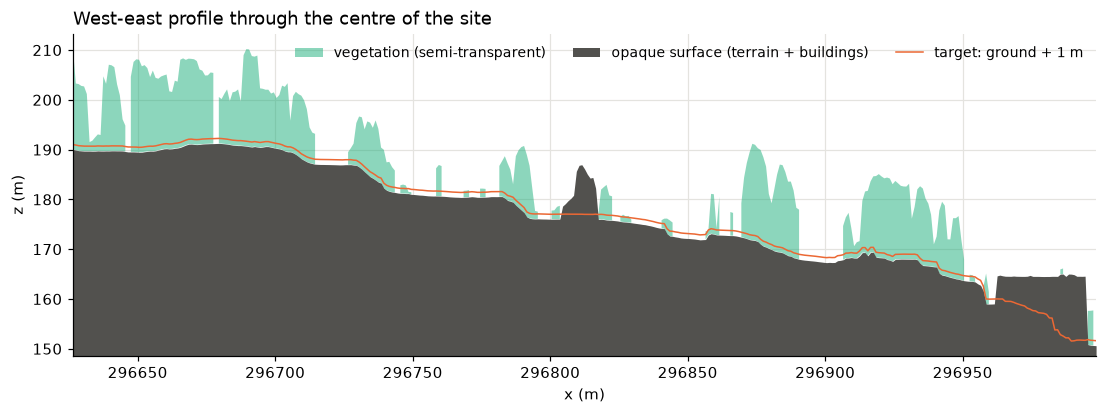

In [11]:
import geopandas as gpd

from src.viewshed import prepare_surfaces, to_pixel

s = prepare_surfaces(cfg)
g = s.grid
per = gpd.read_file(cfg["site"]["gpkg"], layer="perimeter").geometry.iloc[0]
row = to_pixel(g, 0, per.centroid.y)[0]
x = g.xmin + (np.arange(g.width) + 0.5) * g.res

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.fill_between(x, s.z_opaque[row], s.z_veg[row], where=s.z_veg[row] > s.z_opaque[row],
                color="#1baf7a", alpha=0.5, lw=0, label="vegetation (semi-transparent)")
ax.fill_between(x, s.z_opaque[row].min() - 2, s.z_opaque[row], color="#52514e", lw=0,
                label="opaque surface (terrain + buildings)")
ax.plot(x, s.z_tgt[row], color="#eb6834", lw=1, label="target: ground + 1 m")
ax.set_xlim(x[0], x[-1]); ax.set_ylim(s.z_opaque[row].min() - 2, None)
ax.set_xlabel("x (m)"); ax.set_ylabel("z (m)")
ax.set_title("West-east profile through the centre of the site", loc="left")
ax.legend(frameon=False, ncol=3, fontsize=9, loc="upper right")
plt.show()

## 2. An exact traversal of the crossed cells

The surface is a set of **prisms** (one per pixel). The segment from the observer $o$ to the target $t$ is
parametrised by $u \in [0, 1]$; the traversal of Amanatides and Woo (1987) visits, in order, **every** cell
the segment crosses, with the parameters $u_\text{in}$ and $u_\text{out}$ at which it enters and leaves it.
It only needs the step between two row crossings ($\Delta u_r = 1/|\Delta r|$) and between two column
crossings ($\Delta u_c = 1/|\Delta c|$): at each step, it moves to the nearest crossing.

Below, the same stepping as the numba kernel `src.viewshed.ray_tau`, in plain Python, compared with a
naive sampling of the segment every 0.5 pixel:

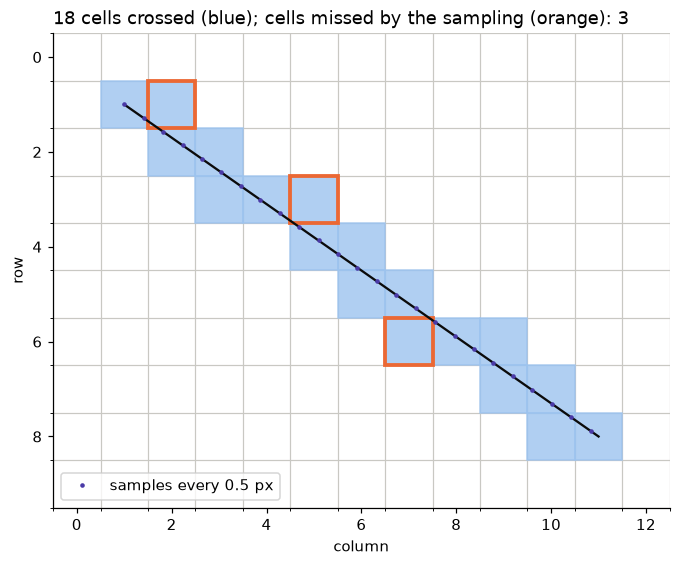

In [12]:
def crossed_cells(r0, c0, r, c):
    '''Cells crossed by the segment between two cell centres, with (u_in, u_out).'''
    dr, dc = r - r0, c - c0
    step_r, step_c = (1 if dr > 0 else -1), (1 if dc > 0 else -1)
    du_r = abs(1.0 / dr) if dr else np.inf        # Δu between two row crossings
    du_c = abs(1.0 / dc) if dc else np.inf        # Δu between two column crossings
    next_r, next_c = 0.5 * du_r, 0.5 * du_c       # first edge half a pixel away
    cr, cc, u_in, out = r0, c0, 0.0, []
    while True:
        u_out = min(next_r, next_c, 1.0)
        out.append((cr, cc, u_in, u_out))
        if u_out >= 1.0:
            return out
        if next_r < next_c:
            cr += step_r; u_in = next_r; next_r += du_r
        elif next_c < next_r:
            cc += step_c; u_in = next_c; next_c += du_c
        else:                                     # exactly through a corner
            cr += step_r; cc += step_c; u_in = next_r; next_r += du_r; next_c += du_c


r0, c0, r1, c1 = 1, 1, 8, 11
exact = crossed_cells(r0, c0, r1, c1)
u = np.arange(0, 1.0001, 0.5 / np.hypot(r1 - r0, c1 - c0))
sampled = {(int(np.floor(r0 + t * (r1 - r0) + 0.5)), int(np.floor(c0 + t * (c1 - c0) + 0.5))) for t in u}
missed = [(r, c) for r, c, *_ in exact if (r, c) not in sampled]

fig, ax = plt.subplots(figsize=(8, 5.6))
for r, c, ui, uo in exact:
    ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, color="#9cc3ef", alpha=0.8))
for r, c in missed:
    ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, ec="#eb6834", lw=2.5))
ax.plot([c0, c1], [r0, r1], color="#0b0b0b", lw=1.5)
ax.plot(c0 + u * (c1 - c0), r0 + u * (r1 - r0), ".", color="#4a3aa7", ms=4, label="samples every 0.5 px")
ax.set_xticks(np.arange(-0.5, 13, 1), minor=True); ax.set_yticks(np.arange(-0.5, 10, 1), minor=True)
ax.grid(which="minor", color="#c9c8c3"); ax.grid(which="major", visible=False)
ax.set_xlim(-0.5, 12.5); ax.set_ylim(9.5, -0.5); ax.set_aspect("equal")
ax.set_xlabel("column"); ax.set_ylabel("row")
ax.set_title(f"{len(exact)} cells crossed (blue); cells missed by the sampling (orange): {len(missed)}",
             loc="left")
ax.legend(loc="lower left", frameon=True)
plt.show()

The sampled version of the engine missed the cells grazed by a corner, which made about 1 % of the cells
falsely visible; the exact traversal was adopted after an **exact referee** showed it. It is also
faster and gives the exact length crossed.

In each crossed cell, with the ray at heights $z_a, z_b$ at the entry and the exit:

- the ray is **blocked** if $\min(z_a, z_b) < z_\text{opaque}$ (the lowest point of the ray in the cell is
  below the top of the prism);
- otherwise, if it passes (partly) under the canopy top $z_\text{veg}$, it accumulates
  $k \cdot f \cdot (u_\text{out} - u_\text{in}) \cdot L$, where $L$ is the 3D length of the whole segment and
  $f$ the fraction of the passage that is below $z_\text{veg}$.

The observer and target cells are excluded by convention (the mast does not hide itself).

## 3. Analytical checks

Two synthetic terrains with a known answer (`tests/test_viewsheds.py` has five).

**A wall.** An observer at height $h$, a wall of height $H_w$ at distance $D_w$, targets at height $t$. By
the intercept theorem, the ray passes above the wall if and only if the target is beyond

$$
D^\star = D_w \, \frac{h - t}{h - H_w}.
$$

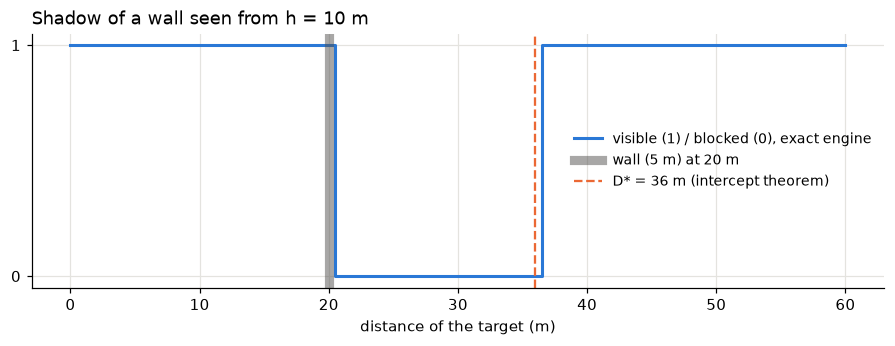

In [13]:
from src.viewshed import optical_depth

N, R0, C0 = 121, 60, 60
flat = lambda v=0.0: np.full((N, N), v)
h, t, Hw, Dw = 10.0, 1.0, 5.0, 20
wall = flat(); wall[:, C0 + Dw] = Hw
tau = optical_depth(wall, wall, flat(), flat(t), R0, C0, h, 60, 1.0)[R0, C0:].astype(float)
d_star = Dw * (h - t) / (h - Hw)

fig, ax = plt.subplots(figsize=(10, 3))
D = np.arange(tau.size)
ax.step(D, np.where(np.isfinite(tau), 1.0, 0.0), where="mid", color="#2a78d6", lw=2,
        label="visible (1) / blocked (0), exact engine")
ax.axvline(Dw, color="#52514e", lw=6, alpha=0.5, label=f"wall ({Hw:g} m) at {Dw} m")
ax.axvline(d_star, color="#eb6834", ls="--", label=f"D* = {d_star:g} m (intercept theorem)")
ax.set_xlabel("distance of the target (m)"); ax.set_yticks([0, 1])
ax.set_title(f"Shadow of a wall seen from h = {h:g} m", loc="left")
ax.legend(frameon=False, fontsize=9, loc="center right")
plt.show()

**An infinite vegetation slab.** Canopy everywhere, with a constant $k$, observer at $h$ and target at
$t$, both under the canopy. Excluding the observer and target cells, the ray crosses $D - 1$ full cells
horizontally, and its 3D length per horizontal metre is $\sqrt{1 + ((t - h)/D)^2}$:

$$
\tau(D) = k\,(D - 1)\,\sqrt{1 + \left(\frac{t - h}{D}\right)^2}.
$$

max relative error: 5.2e-08


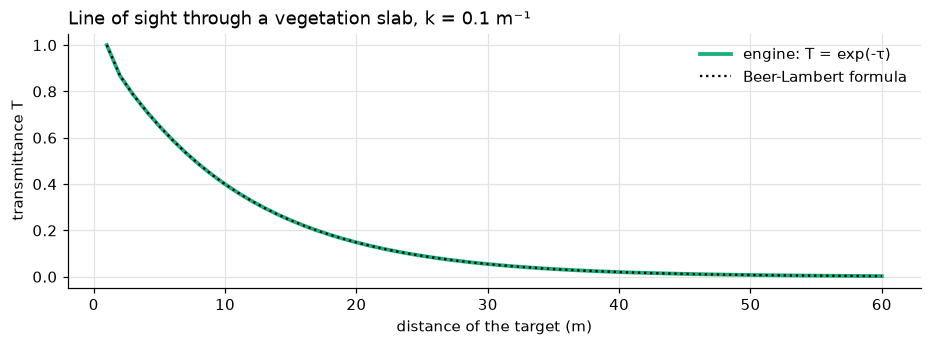

In [14]:
h, t, k = 3.0, 1.0, 0.1
tau = optical_depth(flat(), flat(50.0), flat(k), flat(t), R0, C0, h, 60, 1.0)[R0, C0:].astype(float)
D = np.arange(1, 61)
expected = k * (D - 1) * np.sqrt(1 + ((t - h) / D) ** 2)
print(f"max relative error: {np.max(np.abs(tau[1:61] - expected) / np.maximum(expected, 1e-12)):.1e}")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(D, np.exp(-tau[1:61]), color="#1baf7a", lw=2.5, label="engine: T = exp(-τ)")
ax.plot(D, np.exp(-expected), "k:", lw=1.5, label="Beer-Lambert formula")
ax.set_xlabel("distance of the target (m)"); ax.set_ylabel("transmittance T")
ax.set_title("Line of sight through a vegetation slab, k = 0.1 m⁻¹", loc="left")
ax.legend(frameon=False)
plt.show()

## 4. Visibility from two candidates of the site

Two contrasted supports: a fence mast standing in trees, and a roof corner. For each, the engine returns
$\tau$ on the disc of 400 m (clipped to the grid); the map shows the transmittance $T = e^{-\tau}$ on the
cells where an intruder can stand.

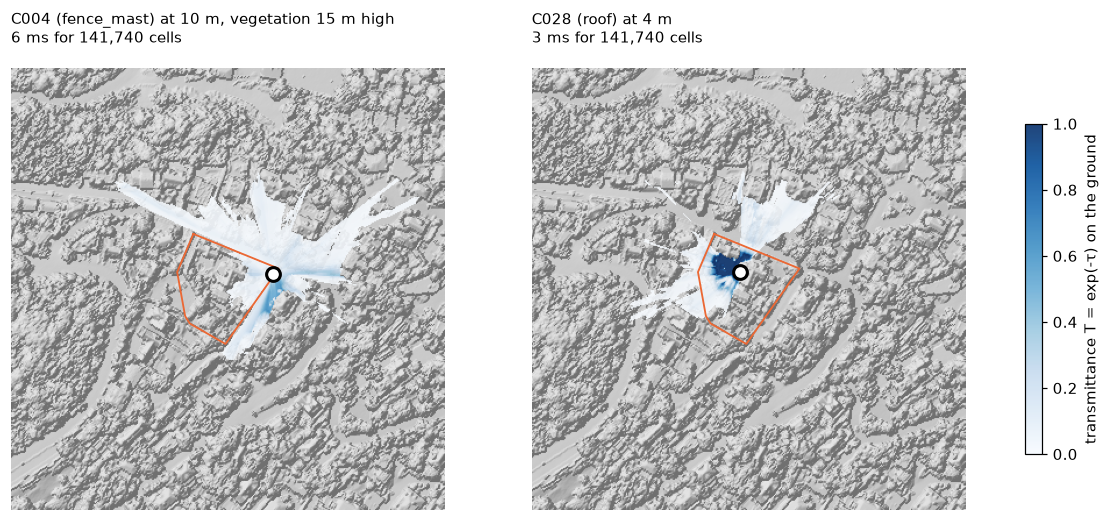

In [15]:
import time

from src.analysis import hillshade
from src.viewshed import compute_tau, read

cand = gpd.read_file(cfg["candidates"]["output"])
mast = cand[cand.support == "fence_mast"].sort_values("h_vegetation").iloc[-1]
roof = cand[cand.support == "roof"].iloc[len(cand[cand.support == "roof"]) // 2]
ground = s.z_opaque < s.z_tgt
dsm = read(Path(cfg["rasters"]["out_dir"]) / "dsm.tif")
hs = hillshade(np.nan_to_num(dsm, nan=np.nanmedian(dsm)))
ext = (g.xmin, g.xmax, g.ymin, g.ymax)

cases = [(mast, 10.0), (roof, 4.0)]
taus = []
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, (c, h) in zip(axes, cases):
    z_obs = c["z_support"] + h
    t0 = time.perf_counter()
    tau = compute_tau(s, c.geometry.x, c.geometry.y, z_obs, cfg).astype(float)
    dt = time.perf_counter() - t0
    taus.append(tau)
    T = np.where(ground, np.exp(-np.where(np.isfinite(tau), tau, np.inf)), np.nan)
    ax.imshow(hs, extent=ext, cmap="Greys_r", vmin=-0.8, vmax=1.4)
    im = ax.imshow(np.where(T > 0.001, T, np.nan), extent=ext, cmap="Blues", vmin=0, vmax=1, alpha=0.9)
    ax.plot(*per.exterior.xy, color="#eb6834", lw=1.2)
    ax.plot(c.geometry.x, c.geometry.y, "o", ms=9, mfc="white", mec="k", mew=2)
    veg = "" if np.isnan(c["h_vegetation"]) else f", vegetation {c['h_vegetation']:.0f} m high"
    ax.set_title(f"{c['id']} ({c['support']}) at {h:g} m{veg}\n{dt * 1e3:.0f} ms for "
                 f"{np.isfinite(tau).sum() + np.isinf(tau).sum():,} cells", loc="left", fontsize=10)
    ax.set_axis_off()
fig.colorbar(im, ax=axes, shrink=0.6, label="transmittance T = exp(-τ) on the ground")
plt.show()

In [16]:
rows = []
for (c, h), tau in zip(cases, taus):
    r0, c0 = to_pixel(g, c.geometry.x, c.geometry.y)
    rr, cc = np.indices(tau.shape)
    dist = np.hypot(rr - r0, cc - c0) * g.res
    for a, b in [(0, 25), (25, 50), (50, 100), (100, 200)]:
        m = ground & (dist >= a) & (dist < b) & ~np.isnan(tau)
        T = np.exp(-np.where(np.isfinite(tau[m]), tau[m], np.inf))
        rows.append({"candidate": f"{c['id']} ({c['support']})", "band_m": f"{a}-{b}",
                     "ground cells": int(m.sum()),
                     "blocked %": round(100 * np.isinf(tau[m]).mean(), 1),
                     "partial (1-50 %) %": round(100 * ((T >= 0.01) & (T < 0.5)).mean(), 1),
                     "clear (≥ 50 %) %": round(100 * (T >= 0.5).mean(), 1)})
pd.DataFrame(rows)

,candidate,band_m,ground cells,blocked %,partial (1-50 %) %,clear (≥ 50 %) %
0,C004 (fence_mast),0-25,1821,0.2,89.2,6.6
1,C004 (fence_mast),25-50,4732,15.7,50.7,1.1
2,C004 (fence_mast),50-100,19372,63.4,10.2,0.0
3,C004 (fence_mast),100-200,68024,94.4,0.6,0.0
4,C028 (roof),0-25,1238,25.4,29.8,42.4
5,C028 (roof),25-50,5522,54.7,31.7,0.2
6,C028 (roof),50-100,18800,74.3,6.1,0.0
7,C028 (roof),100-200,75353,94.4,0.0,0.0


A roof corner sees far but only in the directions that do not cross its own roof; a mast in the trees sees
**through** the branches rather than over them, with a mostly partial visibility. The best location
therefore depends on the sensor (short-range camera or long-range radar), which is exactly what the next
notebook quantifies.

## 5. What an opaque surface model would say

A plain viewshed on the DSM treats a tree like a wall. The same observer, with the DSM as the opaque
surface and no vegetation:

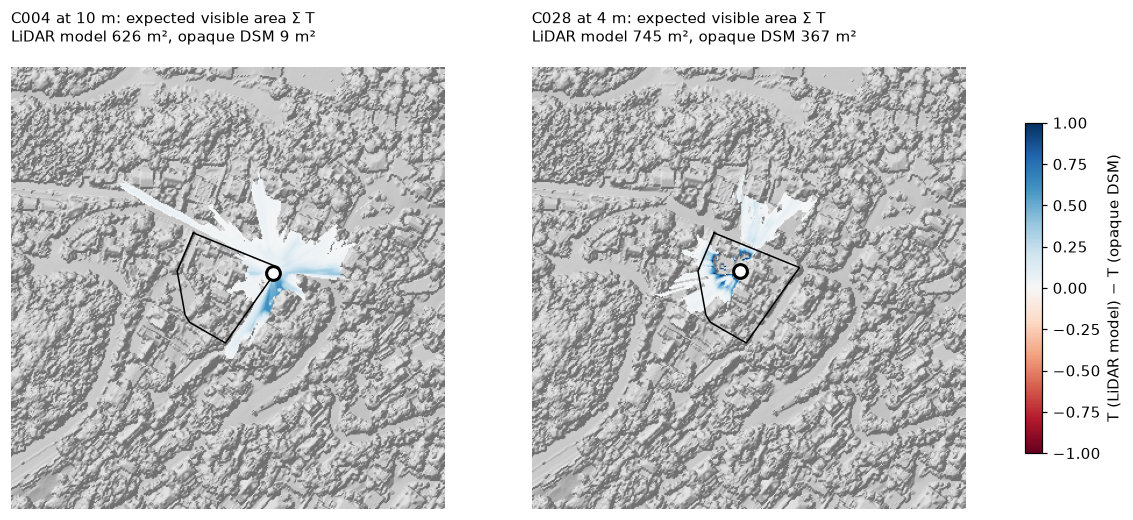

In [17]:
dsm_filled = np.nan_to_num(dsm, nan=np.nanmedian(dsm))
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, (c, h), tau in zip(axes, cases, taus):
    r0, c0 = to_pixel(g, c.geometry.x, c.geometry.y)
    z_obs = c["z_support"] + h
    tau_dsm = optical_depth(dsm_filled, dsm_filled, np.zeros_like(dsm_filled), s.z_tgt, r0, c0, z_obs,
                            int(cfg["viewshed"]["radius_m"]), g.res).astype(float)
    T_lidar = np.exp(-np.where(np.isfinite(tau), tau, np.inf))
    T_dsm = np.where(np.isfinite(tau_dsm), 1.0, 0.0)
    m = ground & ~np.isnan(tau)
    diff = np.where(m, T_lidar - T_dsm, np.nan)
    ax.imshow(hs, extent=ext, cmap="Greys_r", vmin=-0.8, vmax=1.4)
    im = ax.imshow(np.where(np.abs(diff) > 0.01, diff, np.nan), extent=ext, cmap="RdBu", vmin=-1, vmax=1)
    ax.plot(*per.exterior.xy, color="k", lw=1)
    ax.plot(c.geometry.x, c.geometry.y, "o", ms=9, mfc="white", mec="k", mew=2)
    ax.set_title(f"{c['id']} at {h:g} m: expected visible area Σ T\nLiDAR model {T_lidar[m].sum():,.0f} m², "
                 f"opaque DSM {T_dsm[m].sum():,.0f} m²", loc="left", fontsize=10)
    ax.set_axis_off()
fig.colorbar(im, ax=axes, shrink=0.6, label="T (LiDAR model) − T (opaque DSM)")
plt.show()

Blue cells are seen through vegetation that an opaque DSM treats as a wall. For the mast standing in the
trees, the difference is total: its sensor is below the top of the canopy, so the DSM viewshed sees almost
nothing, while the LiDAR model sees partially through the leafless branches. This is the main contribution
of the point cloud to the problem.

## 6. Why it matters for the optimisation

$\tau$ only depends on the position and the height. On this site, the whole catalog needs one computation
per (position, height) pair, while the sensor models and their orientations multiply the configurations:

In [18]:
conf = pd.read_csv(Path(cfg["coverage"]["out_dir"]) / "configs.csv")
n_pairs = conf.groupby(["cand", "h"]).ngroups
print(f"{n_pairs} computations of τ -> {len(conf):,} useful configurations "
      f"({conf.groupby('sensor').size().to_dict()})")

112 computations of τ -> 2,290 useful configurations ({'cam_standard': 648, 'cam_tele': 394, 'cam_wide': 803, 'radar_perimeter': 445})


**Next:** [03. Sensor models](03_sensor_models.ipynb) turns $\tau$ into a detection probability for a
camera and a radar.